# Lab Assignment 11: Coreference Resolution & Question Answering

**Objective:**
In this lab you will implement and evaluate two core NLP tasks:
(A) **Coreference Resolution** using a SpanBERT-based model, and
(B) **Question Answering** by fine-tuning BERT on the SQuAD reading comprehension dataset.
You will also explore the connection between the two tasks.

**Task:** (A) Coreference chain detection and evaluation. (B) Span extraction from a passage given a question.

**Learning outcomes:**
1. Understand and use a SpanBERT-based coreference model.
2. Implement B-cubed evaluation for coreference.
3. Fine-tune (or use a fine-tuned) BERT model for span-based QA.
4. Implement SQuAD-style EM and F1 evaluation.
5. Explore the Open-Domain QA retriever-reader pipeline.

| Part | Topic | Points |
|---|---|---|
| 1 | Setup & Data | 5 |
| 2 | Coreference: SpanBERT Model | 20 |
| 3 | Coreference: Manual Analysis & Evaluation | 20 |
| 4 | Question Answering: BERT for SQuAD | 25 |
| 5 | QA Evaluation: EM and F1 | 15 |
| 6 | Open-Domain QA Pipeline | 10 |
| 7 | Connecting Coref and QA | 5 |
| | **Total** | **100** |

**Submission:** Complete all `# TODO` sections and all markdown answers. Run **Kernel > Restart & Run All** before submitting.


---
## Theory Recap

**Coreference Resolution** groups all text spans (mentions) that refer to the same real-world entity.
Three types of mentions: *pronouns*, *named entities*, and *noun phrases*.

**Mention-Ranking** scores each mention against all preceding candidates:
$$s(i,j) = s_m(i) + s_m(j) + s_a(i,j)$$
A dummy antecedent ε allows the model to start a new cluster.

**SpanBERT** represents span (i,j) as: $g(i,j) = [h_i, h_j, \tilde{h}(i,j), \phi(i,j)]$

**BERT for QA (SQuAD):** Fine-tune with two linear classifiers on the final hidden states:
$$P_{start}(i) = \text{softmax}(W_{start}\, h_i), \quad P_{end}(i) = \text{softmax}(W_{end}\, h_i)$$
The predicted answer is $P[\text{argmax}(P_{start}) : \text{argmax}(P_{end})+1]$.


**B-cubed Precision/Recall** for mention $m$:
$$P_m = \frac{|C_{gold}(m) \cap C_{sys}(m)|}{|C_{sys}(m)|}, \quad R_m = \frac{|C_{gold}(m) \cap C_{sys}(m)|}{|C_{gold}(m)|}$$


---
## Part 1: Setup and Data (5 points)

### 1.1 Install and Import Libraries


In [1]:
# Install required libraries (%pip installs into the kernel's own environment)
%pip install -q fastcoref transformers datasets evaluate scikit-learn spacy matplotlib
import sys
!{sys.executable} -m spacy download en_core_web_sm -q
# If anything was newly installed, restart the kernel once and then Run All.

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import random
import re
import string
import logging
from collections import Counter

import numpy as np
import torch
import matplotlib.pyplot as plt
import transformers
from transformers import pipeline, AutoTokenizer, AutoModelForQuestionAnswering
from datasets import load_dataset
from fastcoref import FCoref

# ── Compatibility fix (same as the tutorial): fastcoref 2.1.6 was written for
#    transformers 4.x. transformers 5.x expects models to call post_init()
#    (which sets `all_tied_weights_keys`); FCorefModel doesn't, so we call it here.
import fastcoref.modeling as _fc_modeling
if int(transformers.__version__.split('.')[0]) >= 5 and \
        not getattr(_fc_modeling.FCorefModel, '_patched_post_init', False):
    _orig_init = _fc_modeling.FCorefModel.__init__
    def _patched_init(self, *args, **kwargs):
        _orig_init(self, *args, **kwargs)
        if not hasattr(self, 'all_tied_weights_keys'):
            self.post_init()
    _fc_modeling.FCorefModel.__init__ = _patched_init
    _fc_modeling.FCorefModel._patched_post_init = True

# Quieter logs (fastcoref prints every HTTP request at INFO level)
logging.getLogger('httpx').setLevel(logging.WARNING)
logging.getLogger('fastcoref').setLevel(logging.WARNING)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'torch {torch.__version__} | transformers {transformers.__version__} | device = {DEVICE}')

torch 2.11.0+cu130 | transformers 5.20.2 | device = cuda


### 1.2 Test Texts for Coreference
Use the following texts for Parts 2 and 3. **Do not change them.**


In [3]:
TEXT_1 = (
    'Akhila met Prajwal at the local park. '
    "Akhila's son Akash was just two months younger than her son Prajwal. "
    'She resigned herself to make Akash the best tree in the play. '
    'She bought him a brown T-shirt to represent the trunk.'
)

TEXT_2 = (
    'Barack Obama was born in Hawaii. '
    'He served as the 44th President of the United States. '
    'Obama attended Columbia University. '
    'His presidency lasted from 2009 to 2017.'
)

TEXT_3 = (
    'Maria Curie was a Polish-born physicist and chemist. '
    'She was the first woman to win a Nobel Prize. '
    'In 1906 she became the first woman professor at the University of Paris. '
    'Curie discovered polonium and radium with her husband Pierre.'
)

print('Sample texts loaded.')

Sample texts loaded.


---
## Part 2: Coreference Resolution using SpanBERT (20 points)

### 2.1 Load the Model and Run Prediction
Load the `FCoref` model and run coreference resolution on **TEXT_1**, **TEXT_2**, and **TEXT_3**.
Print the coreference clusters (as strings) for each text.


In [4]:
coref_model = FCoref(device=DEVICE)

TEXTS = [TEXT_1, TEXT_2, TEXT_3]
coref_preds = coref_model.predict(texts=TEXTS)

for i, (text, pred) in enumerate(zip(TEXTS, coref_preds), 1):
    print(f'--- Text {i} ---')
    print(text)
    print()
    clusters_str  = pred.get_clusters(as_strings=True)
    clusters_span = pred.get_clusters(as_strings=False)
    for j, (cluster, spans) in enumerate(zip(clusters_str, clusters_span), 1):
        print(f'  Cluster {j}: ' + ' → '.join(cluster))
        print(f'             char offsets: {spans}')
    print()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

Map:   0%|          | 0/3 [00:00<?, ? examples/s]

Inference:   0%|          | 0/3 [00:00<?, ?it/s]

--- Text 1 ---
Akhila met Prajwal at the local park. Akhila's son Akash was just two months younger than her son Prajwal. She resigned herself to make Akash the best tree in the play. She bought him a brown T-shirt to represent the trunk.

  Cluster 1: Akhila → Akhila's → her → She → herself → She
             char offsets: [(0, 6), (38, 46), (90, 93), (107, 110), (120, 127), (169, 172)]
  Cluster 2: Prajwal → her son Prajwal
             char offsets: [(11, 18), (90, 105)]
  Cluster 3: Akhila's son Akash → Akash → him
             char offsets: [(38, 56), (136, 141), (180, 183)]

--- Text 2 ---
Barack Obama was born in Hawaii. He served as the 44th President of the United States. Obama attended Columbia University. His presidency lasted from 2009 to 2017.

  Cluster 1: Barack Obama → He → Obama → His
             char offsets: [(0, 12), (33, 35), (87, 92), (123, 126)]

--- Text 3 ---
Maria Curie was a Polish-born physicist and chemist. She was the first woman to win a Nobel Prize. In 

### 2.2 Markdown Questions
Answer in the cell below:
1. For TEXT_1, list all the coreference clusters the model found. Are they correct?
2. Which mentions were **missed** (false negatives) and which were **wrong** (false positives)?
3. Why might the model confuse 'her son' in TEXT_1? What linguistic phenomenon makes this hard?


**Your answers:**

1. **Clusters found by FCoref for TEXT_1** (output of 2.1):

   | # | Cluster | Char offsets |
   |---|---|---|
   | 1 | Akhila → Akhila's → her → She → herself → She | (0,6) (38,46) (90,93) (107,110) (120,127) (169,172) |
   | 2 | Prajwal → her son Prajwal | (11,18) (90,105) |
   | 3 | Akhila's son Akash → Akash → him | (38,56) (136,141) (180,183) |

   **Gold clusters** (what a human annotator would mark): {Akhila, Akhila's, She, herself, She}, {Akhila's son Akash, Akash, him}, {Prajwal, her son Prajwal}, plus a separate singleton for the possessor *her* in "her son Prajwal" (Prajwal's mother, who is never named).

   The output is **mostly correct**. Clusters 2 and 3 are fully correct. The model resolves *him* to Akash (the boy dressed as the tree) rather than to Prajwal, and it handles the nested possessive *Akhila's* (38–46) inside *Akhila's son Akash* (38–56). In cluster 1, *She*, *herself* and *She* are correctly linked to Akhila. The one error is *her* (90–93).

2. **False positive (wrong link):** *her* (90–93) in Akhila's cluster. Akash is *just two months younger* than "her son Prajwal", and one mother cannot have two sons born two months apart. So *her* must be a **different woman** (Prajwal's mother). This single wrong link makes cluster 1 impure. In B-cubed terms, each of the five true Akhila mentions gets P_m = 5/6, and *her* itself gets P_m = 1/6.

   **False negatives (missed):** none. All 10 coreferent mentions of Akhila (5), Akash (3) and Prajwal (2) are found. The mentions the model does not output (*the local park*, *the best tree*, *the play*, *a brown T-shirt*, *the trunk*) are **singletons**, which FCoref drops by design (OntoNotes convention), so they are not errors. The only real loss is the entity "Prajwal's mother": her one mention *her* was absorbed into the wrong cluster instead of being left as a singleton. *The trunk* is related to *the best tree* by **bridging** (part-of), not coreference, so the model is right not to link them.

3. **Why 'her son' is hard:**
   - **Nested mentions:** "her son Prajwal" (90–105) contains two mentions of *different* entities: the whole NP (Prajwal) and the possessive *her* (90–93), which refers to his mother. The output shows exactly this nesting: the model put the inner span in Akhila's cluster and the outer span in Prajwal's cluster. A span-based model has to score these overlapping spans separately.
   - **Apposition:** "her son" and "Prajwal" stand side by side in apposition. The model has to see that they are the same person and choose the span boundaries.
   - **Ambiguous / missing antecedent:** *her* agrees in gender and number only with **Akhila**, who is the only woman named and the most salient entity (subject of sentence 1, possessor in "Akhila's son"). Every surface cue (gender agreement, recency, salience) points to Akhila. Ruling her out takes **commonsense / world knowledge**: siblings cannot be two months apart, and the contrast "*Akhila's* son … *her* son" implies two different mothers. This is the Winograd-schema problem: the referent depends on meaning, not syntax, and here the true antecedent is not even in the text. The names add to the difficulty. *Akhila* and *Prajwal* are rare in English training data, so name→gender knowledge helps less (spaCy even tags *Prajwal* as PRODUCT in 2.3).

### 2.3 Mention Detection: Types and Counts
Write a function `count_mention_types(text)` that uses spaCy to count the number of:
- Pronouns (using POS tags)
- Named entities (using NER)
- Noun phrases (using noun chunks)
Apply it to all three texts. Print results in a table.


In [5]:
import spacy
nlp = spacy.load('en_core_web_sm')

def count_mention_types(text):
    """
    Returns a dict: {'pronouns': int, 'named_entities': int, 'noun_phrases': int}
    """
    doc = nlp(text)
    return {
        'pronouns':       sum(1 for tok in doc if tok.pos_ == 'PRON'),
        'named_entities': len(doc.ents),
        'noun_phrases':   sum(1 for _ in doc.noun_chunks),
    }

print(f'{"Text":<8}{"Pronouns":>10}{"Named entities":>16}{"Noun phrases":>14}')
print('-' * 48)
for i, text in enumerate([TEXT_1, TEXT_2, TEXT_3], 1):
    counts = count_mention_types(text)
    print(f'{"Text " + str(i):<8}{counts["pronouns"]:>10}{counts["named_entities"]:>16}{counts["noun_phrases"]:>14}')

# Which mentions were detected (for reference)
print()
for i, text in enumerate([TEXT_1, TEXT_2, TEXT_3], 1):
    doc = nlp(text)
    print(f'Text {i}')
    print(f'  pronouns    : {[tok.text for tok in doc if tok.pos_ == "PRON"]}')
    print(f'  entities    : {[(ent.text, ent.label_) for ent in doc.ents]}')
    print(f'  noun chunks : {[chunk.text for chunk in doc.noun_chunks]}')

Text      Pronouns  Named entities  Noun phrases
------------------------------------------------
Text 1           5               5            15
Text 2           2               7             8
Text 3           3               8            15

Text 1
  pronouns    : ['her', 'She', 'herself', 'She', 'him']
  entities    : [('Akhila', 'PERSON'), ('Akhila', 'PERSON'), ('Akash', 'PERSON'), ('just two months', 'DATE'), ('Prajwal', 'PRODUCT')]
  noun chunks : ['Akhila', 'Prajwal', 'the local park', "Akhila's son", 'Akash', 'her son', 'Prajwal', 'She', 'herself', 'Akash', 'the play', 'She', 'him', 'a brown T-shirt', 'the trunk']
Text 2
  pronouns    : ['He', 'His']
  entities    : [('Barack Obama', 'PERSON'), ('Hawaii', 'GPE'), ('44th', 'ORDINAL'), ('the United States', 'GPE'), ('Obama', 'PERSON'), ('Columbia University', 'ORG'), ('2009', 'DATE')]
  noun chunks : ['Barack Obama', 'Hawaii', 'He', 'the 44th President', 'the United States', 'Obama', 'Columbia University', 'His presidency']
Tex

---
## Part 3: Manual Evaluation with B-cubed (20 points)

### 3.1 Gold Standard Clusters (TEXT_2 Only)
For TEXT_2, define the **gold standard** coreference clusters using the mention offsets from the text.
The character-level mentions are given — use them as entity labels (strings).


In [6]:
# Gold clusters for TEXT_2 (mention strings as identifiers)
GOLD_TEXT2 = [
    {'Barack Obama', 'He', 'Obama', 'His'},  # Cluster 1: the person
    {'the United States'},                    # Cluster 2: the country
    {'Columbia University'},                  # Cluster 3: the university
    {'Hawaii'},                               # Singleton: Hawaii
]
# Note: singletons are valid gold clusters too
print('Gold clusters defined:', len(GOLD_TEXT2), 'clusters')

Gold clusters defined: 4 clusters


### 3.2 Extract System Clusters for TEXT_2
Extract the coreference clusters that the model predicted for TEXT_2 (from Part 2.1).
Convert them to sets of mention strings (as above) for comparison.


In [7]:
# System clusters for TEXT_2 (index 1 in coref_preds from Part 2.1)
system_clusters_text2 = [set(c) for c in coref_preds[1].get_clusters(as_strings=True)]

# FCoref only returns clusters with >= 2 mentions (singletons are discarded).
# The gold clusters contain singletons, so every gold mention the model left
# unclustered is added back as its own singleton cluster — the model implicitly
# predicts it refers to an entity mentioned only once.
clustered = set().union(*system_clusters_text2)
for gold_cluster in GOLD_TEXT2:
    for mention in gold_cluster:
        if mention not in clustered:
            system_clusters_text2.append({mention})

print('System clusters for TEXT_2:')
for c in system_clusters_text2:
    print('  ', c)

System clusters for TEXT_2:
   {'He', 'Barack Obama', 'Obama', 'His'}
   {'the United States'}
   {'Columbia University'}
   {'Hawaii'}


### 3.3 Implement and Compute B-cubed
Implement the `bcubed(gold_clusters, system_clusters)` function and compute B-cubed P, R, F1 for TEXT_2.


In [8]:
def bcubed(gold_clusters, system_clusters):
    """
    Compute B-cubed Precision, Recall, F1.
    Arguments:
        gold_clusters:   list of sets of mention strings (gold standard)
        system_clusters: list of sets of mention strings (system output)
    Returns: (precision, recall, f1) — all floats rounded to 3 decimal places

    Algorithm:
    1. Build a mention → cluster_index lookup for gold and system.
    2. For each mention m:
         overlap = |gold_cluster(m) ∩ system_cluster(m)|
         P_m = overlap / |system_cluster(m)|
         R_m = overlap / |gold_cluster(m)|
    3. Average P_m and R_m across all mentions.
    4. Compute F1 from averaged P and R.
    """
    # 1. mention → cluster index
    gold_idx = {m: i for i, c in enumerate(gold_clusters)   for m in c}
    sys_idx  = {m: i for i, c in enumerate(system_clusters) for m in c}

    # Evaluate over all mentions; one missing from a side counts as a singleton there
    mentions = set(gold_idx) | set(sys_idx)
    if not mentions:
        return 0.0, 0.0, 0.0

    # 2. per-mention precision and recall
    p_sum = r_sum = 0.0
    for m in mentions:
        gold_c = set(gold_clusters[gold_idx[m]])  if m in gold_idx else {m}
        sys_c  = set(system_clusters[sys_idx[m]]) if m in sys_idx  else {m}
        overlap = len(gold_c & sys_c)
        p_sum += overlap / len(sys_c)
        r_sum += overlap / len(gold_c)

    # 3. average over mentions
    P = p_sum / len(mentions)
    R = r_sum / len(mentions)

    # 4. F1
    F1 = 2 * P * R / (P + R) if (P + R) > 0 else 0.0
    return round(P, 3), round(R, 3), round(F1, 3)

# Sanity checks: tutorial Case 1 should give 0.595, a perfect system 1.0
print('Sanity (tutorial case 1):', bcubed([{'A', 'B', 'C', 'D'}, {'E', 'F', 'G'}],
                                          [{'A', 'B', 'C', 'E'}, {'D', 'F', 'G'}]))
print('Sanity (perfect system) :', bcubed(GOLD_TEXT2, GOLD_TEXT2))
print()

# Compute B-cubed for TEXT_2
P, R, F1 = bcubed(GOLD_TEXT2, system_clusters_text2)
print(f'B-cubed for TEXT_2: P={P}, R={R}, F1={F1}')

Sanity (tutorial case 1): (0.595, 0.595, 0.595)
Sanity (perfect system) : (1.0, 1.0, 1.0)

B-cubed for TEXT_2: P=1.0, R=1.0, F1=1.0


### 3.4 Short Questions
1. What does it mean when B-cubed Precision is 1.0 but Recall is low?
2. What does it mean when B-cubed Recall is 1.0 but Precision is low?
3. Besides B-cubed, name two other standard coreference evaluation metrics used for OntoNotes.


**Your answers:**

*TEXT_2 result (3.3):* **P = R = F1 = 1.0.** FCoref's single cluster {Barack Obama, He, Obama, His} is identical to gold cluster 1. The other three gold entities (Hawaii, the United States, Columbia University) were correctly left unclustered and enter as singletons. The sanity checks reproduce the tutorial values (0.595 and 1.0).

1. **P = 1.0 but low R → under-merging.** Every system cluster holds mentions of only one gold entity (no wrong links), but real entities are **split** into several smaller clusters or left as singletons, so each mention recovers only part of its gold cluster. The extreme case is outputting every mention as a singleton: P = 1.0 and R = the average of 1/|gold cluster|.

2. **R = 1.0 but low P → over-merging.** Every gold cluster sits entirely inside some system cluster (no missed links), but system clusters **lump together different entities**. The extreme case is putting all mentions into one big cluster: R = 1.0 and P is very low. TEXT_1 shows a small example: adding the wrong *her* to Akhila's cluster leaves recall at 1.0 for those mentions but drops their precision to 5/6.

3. **MUC** (Vilain et al., 1995) is **link-based**: it counts how many coreference links you need to add or remove to turn the system clusters into the gold ones. **CEAF** (Luo, 2005; the CEAF-e / CEAF-m variants) is **entity-alignment-based**: it finds the best one-to-one mapping between gold and system entities and scores their similarity. The official CoNLL-2012 (OntoNotes) score is the average F1 of **MUC, B³ and CEAF-e**. (BLANC and LEA are other metrics in use.)

---
## Part 4: Question Answering with BERT (25 points)

### 4.1 Setup the QA Model
Load `deepset/bert-base-cased-squad2` using HuggingFace `AutoTokenizer` and `AutoModelForQuestionAnswering`.


In [9]:
model_name = 'deepset/bert-base-cased-squad2'
tokenizer  = AutoTokenizer.from_pretrained(model_name)
qa_model   = AutoModelForQuestionAnswering.from_pretrained(model_name).to(DEVICE)
qa_model.eval()
print(f'{model_name} loaded on {qa_model.device}')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

deepset/bert-base-cased-squad2 loaded on cuda:0


### 4.2 Implement Span Extraction
Implement `extract_answer(question, context, tokenizer, model)` that:
1. Tokenizes the (question, context) pair.
2. Runs the model.
3. Finds the best valid span: `start <= end` and both within the context tokens.
4. Returns the answer string and its score (start_logit[s] + end_logit[e]).


In [10]:
import torch

def best_span(start_logits, end_logits, ctx_start, ctx_end, max_answer_len=50):
    """
    Search every span (s, e) with ctx_start <= s <= e <= ctx_end and e - s < max_answer_len.
    Returns (s, e, score) maximising start_logits[s] + end_logits[e].
    """
    start, end = start_logits.tolist(), end_logits.tolist()
    best_s, best_e, best_score = ctx_start, ctx_start, float('-inf')
    for s in range(ctx_start, ctx_end + 1):
        for e in range(s, min(s + max_answer_len, ctx_end + 1)):   # end >= start, length cap
            score = start[s] + end[e]
            if score > best_score:
                best_s, best_e, best_score = s, e, score
    return best_s, best_e, best_score


def extract_answer(question, context, tokenizer, model, max_answer_len=50):
    """
    Extract answer span from context given a question.
    Arguments:
        question:       str
        context:        str
        tokenizer:      HuggingFace tokenizer
        model:          AutoModelForQuestionAnswering
        max_answer_len: maximum number of tokens in the answer span
    Returns:
        answer: str — the extracted answer text
        score:  float — start_logit[s] + end_logit[e]
    Requirements:
      - Must enforce end >= start
      - Must enforce end - start < max_answer_len
      - Must use torch.no_grad() for inference
      - Must handle the [CLS] and [SEP] tokens correctly
        (answer must come from the context portion, not the question)
    """
    # 1. Tokenise: [CLS] question [SEP] context [SEP]
    #    offset_mapping lets us cut the answer straight out of the original context string
    inputs = tokenizer(question, context, return_tensors='pt',
                       truncation='only_second', max_length=512,
                       return_offsets_mapping=True)
    offsets = inputs['offset_mapping'][0].tolist()

    # sequence_ids: None for [CLS]/[SEP], 0 for question tokens, 1 for context tokens
    seq_ids = inputs.sequence_ids(0)
    ctx_tokens = [i for i, sid in enumerate(seq_ids) if sid == 1]
    ctx_start, ctx_end = ctx_tokens[0], ctx_tokens[-1]

    # 2. Forward pass
    model_inputs = {k: v.to(model.device) for k, v in inputs.items() if k != 'offset_mapping'}
    with torch.no_grad():
        outputs = model(**model_inputs)
    start_logits = outputs.start_logits[0].cpu()
    end_logits   = outputs.end_logits[0].cpu()

    # 3. Best valid span inside the context only (never question, [CLS] or [SEP])
    s, e, score = best_span(start_logits, end_logits, ctx_start, ctx_end, max_answer_len)

    # 4. Snap to whole words: the span may start/end on a sub-word piece
    #    (e.g. '##urie' of 'C ##urie'), so extend it to that word's first/last piece.
    #    The score stays that of the span the model chose.
    word_ids = inputs.word_ids(0)
    while s > ctx_start and word_ids[s - 1] == word_ids[s]:
        s -= 1
    while e < ctx_end and word_ids[e + 1] == word_ids[e]:
        e += 1

    # 5. Map the token span back to characters of the original context
    answer = context[offsets[s][0]:offsets[e][1]]
    return answer, score

### 4.3 Test on SQuAD-Style Examples
Test your function on the following (passage, question, gold_answer) triples. Print the predicted answer and score.


In [11]:
squad_examples = [
    {
        'context':  'The Tesla family moved to Gospic in 1862, where Tesla father worked as a pastor. '
                    'Nikola completed Primary School and then the Lower Real Gymnasium.',
        'question': 'Where did the Tesla family move in 1862?',
        'gold':     'Gospic'
    },
    {
        'context':  'In 1861, Tesla attended the Primary School in Smiljan '
                    'where he studied German, arithmetic, and religion.',
        'question': 'What subjects did Tesla study at Primary School?',
        'gold':     'German, arithmetic, and religion'
    },
    {
        'context':  'Kannada language is the official language of Karnataka and '
                    'spoken as a native language by about 66.54 percent of the people as of 2011. '
                    'Other minorities were Urdu (10.83 percent) and Telugu (5.84 percent).',
        'question': 'What percentage of people speak Kannada natively?',
        'gold':     '66.54 percent'
    },
]

for i, ex in enumerate(squad_examples, 1):
    pred, score = extract_answer(ex['question'], ex['context'], tokenizer, qa_model)
    print(f'Example {i}')
    print(f'  Q    : {ex["question"]}')
    print(f'  Pred : "{pred}"  (score={score:.2f})')
    print(f'  Gold : "{ex["gold"]}"')
    print()

Example 1
  Q    : Where did the Tesla family move in 1862?
  Pred : "Gospic"  (score=18.04)
  Gold : "Gospic"

Example 2
  Q    : What subjects did Tesla study at Primary School?
  Pred : "German, arithmetic, and religion"  (score=13.27)
  Gold : "German, arithmetic, and religion"

Example 3
  Q    : What percentage of people speak Kannada natively?
  Pred : "66.54"  (score=17.96)
  Gold : "66.54 percent"



### 4.4 Visualise Start and End Logits
For the first example in `squad_examples`, plot a bar chart of the start logits and end logits (one plot each), with a vertical line marking the predicted start/end position. Label the x-axis with token strings.


Predicted span: tokens [18..20] = "Gospic"  (score=18.04)


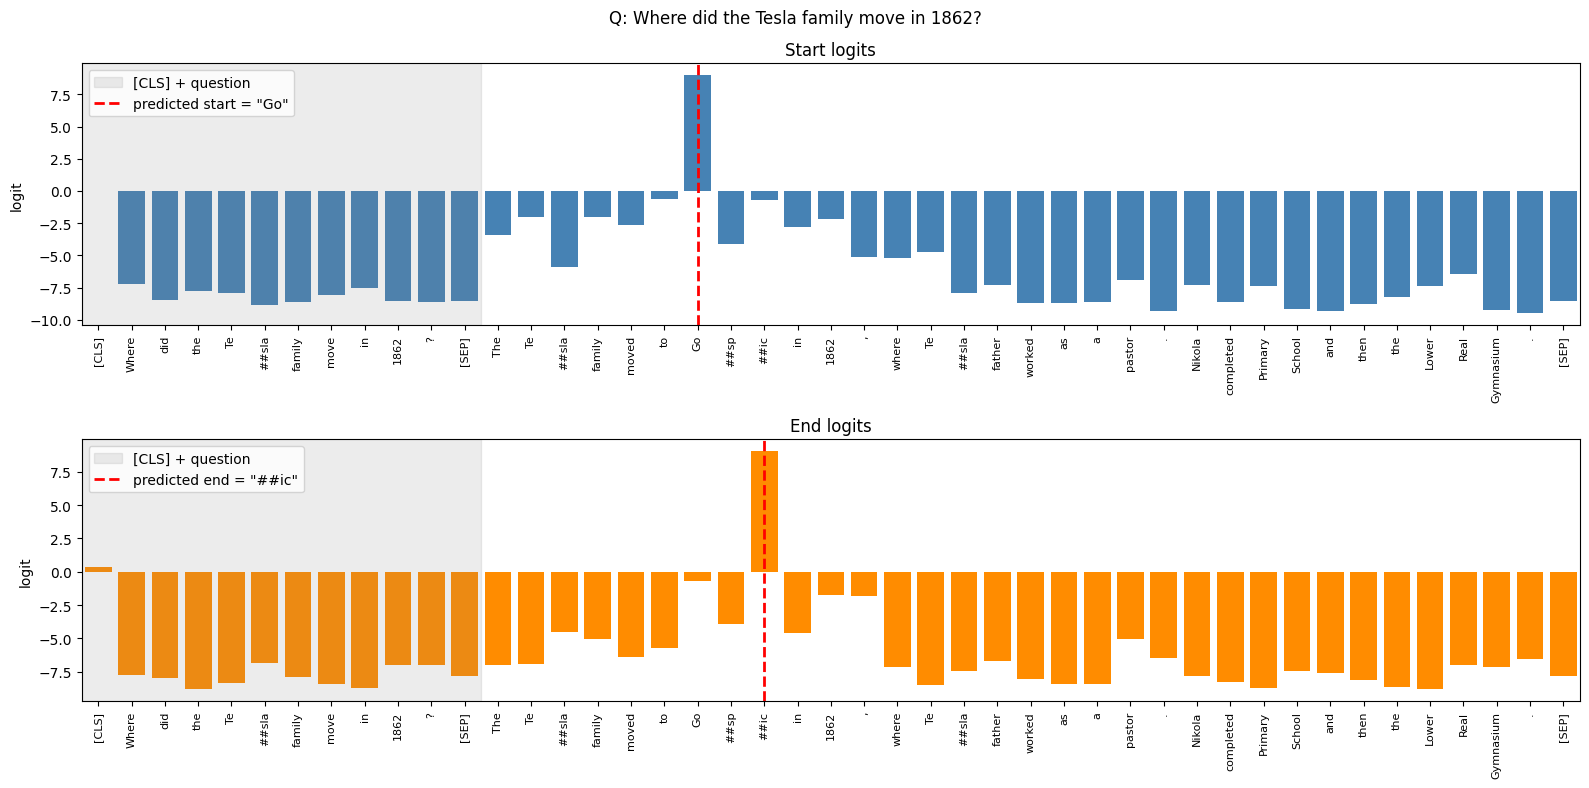

In [12]:
ex = squad_examples[0]

enc = tokenizer(ex['question'], ex['context'], return_tensors='pt',
                truncation='only_second', max_length=512)
tokens  = tokenizer.convert_ids_to_tokens(enc['input_ids'][0])
seq_ids = enc.sequence_ids(0)
ctx_tokens = [i for i, sid in enumerate(seq_ids) if sid == 1]

with torch.no_grad():
    out = qa_model(**{k: v.to(qa_model.device) for k, v in enc.items()})
start_logits = out.start_logits[0].cpu()
end_logits   = out.end_logits[0].cpu()

pred_s, pred_e, pred_score = best_span(start_logits, end_logits, ctx_tokens[0], ctx_tokens[-1])
pred_text = tokenizer.convert_tokens_to_string(tokens[pred_s:pred_e + 1])
print(f'Predicted span: tokens [{pred_s}..{pred_e}] = "{pred_text}"  (score={pred_score:.2f})')

x = np.arange(len(tokens))
fig, axes = plt.subplots(2, 1, figsize=(16, 8))
panels = [
    (axes[0], start_logits, pred_s, 'Start', 'steelblue'),
    (axes[1], end_logits,   pred_e, 'End',   'darkorange'),
]
for ax, logits, pos, name, color in panels:
    ax.bar(x, logits.numpy(), color=color)
    ax.axvspan(-0.5, ctx_tokens[0] - 0.5, color='grey', alpha=0.15, label='[CLS] + question')
    ax.axvline(pos, color='red', linestyle='--', lw=2, label=f'predicted {name.lower()} = "{tokens[pos]}"')
    ax.set_xticks(x)
    ax.set_xticklabels(tokens, rotation=90, fontsize=8)
    ax.set_xlim(-0.5, len(tokens) - 0.5)
    ax.set_ylabel('logit')
    ax.set_title(f'{name} logits')
    ax.legend(loc='upper left')
fig.suptitle(f'Q: {ex["question"]}')
plt.tight_layout()
plt.show()

### 4.5 Unanswerable Questions (SQuAD v2.0)
The model `deepset/bert-base-cased-squad2` was trained on SQuAD v2.0 which includes unanswerable questions. Run the model on the context and question below. Look at the score — what does a low/high score mean?


In [13]:
context_v2  = 'Tesla attended school in Smiljan where he studied German and arithmetic.'
question_v2 = 'What year was Tesla born?'

def no_answer_score(question, context, tokenizer, model):
    """SQuAD v2.0 null score: start_logit[CLS] + end_logit[CLS] ([CLS] is position 0)."""
    enc = tokenizer(question, context, return_tensors='pt', truncation='only_second', max_length=512)
    with torch.no_grad():
        out = model(**{k: v.to(model.device) for k, v in enc.items()})
    return out.start_logits[0, 0].item() + out.end_logits[0, 0].item()

ans_v2, score_v2 = extract_answer(question_v2, context_v2, tokenizer, qa_model)
null_v2 = no_answer_score(question_v2, context_v2, tokenizer, qa_model)
print(f'Q: {question_v2}')
print(f'C: {context_v2}')
print(f'Best span       : "{ans_v2}"  (span score = {score_v2:.2f})')
print(f'No-answer score : {null_v2:.2f}  (start[CLS] + end[CLS])')
print('Decision        :', 'NO ANSWER' if null_v2 > score_v2 else f'ANSWER = "{ans_v2}"')
print()

# Compare with the answerable examples from 4.3
print(f'{"Question":<52}{"Best span":<36}{"Span":>8}{"Null":>8}  Decision')
print('-' * 114)
rows = [(e['question'], e['context']) for e in squad_examples] + [(question_v2, context_v2)]
for q, c in rows:
    a, s = extract_answer(q, c, tokenizer, qa_model)
    n = no_answer_score(q, c, tokenizer, qa_model)
    print(f'{q[:50]:<52}{a[:34]:<36}{s:>8.2f}{n:>8.2f}  {"NO ANSWER" if n > s else "answer"}')

Q: What year was Tesla born?
C: Tesla attended school in Smiljan where he studied German and arithmetic.
Best span       : "Tesla attended school in Smiljan"  (span score = -8.62)
No-answer score : 1.18  (start[CLS] + end[CLS])
Decision        : NO ANSWER

Question                                            Best span                               Span    Null  Decision
------------------------------------------------------------------------------------------------------------------
Where did the Tesla family move in 1862?            Gospic                                 18.04    0.35  answer
What subjects did Tesla study at Primary School?    German, arithmetic, and religion       13.27   -1.91  answer
What percentage of people speak Kannada natively?   66.54                                  17.96    1.27  answer
What year was Tesla born?                           Tesla attended school in Smiljan       -8.62    1.18  NO ANSWER


**Your answer:**

**Our results (4.5):**

| Question | Best span | Span score | Null (`[CLS]`) score | Decision |
|---|---|---|---|---|
| Where did the Tesla family move in 1862? | Gospic | 18.04 | 0.35 | answer |
| What subjects did Tesla study at Primary School? | German, arithmetic, and religion | 13.27 | −1.91 | answer |
| What percentage of people speak Kannada natively? | 66.54 | 17.96 | 1.27 | answer |
| **What year was Tesla born?** | Tesla attended school in Smiljan | **−8.62** | **1.18** | **NO ANSWER** |

The passage says nothing about when Tesla was born. `extract_answer` has to pick a context span, so it returns "Tesla attended school in Smiljan", which is just the phrase that overlaps the question word *Tesla*. Its score is **−8.62**, about 22–27 points below the answerable examples (13.27–18.04) and below the null score of 1.18, so the decision is **NO ANSWER**. The null score barely changes across the four questions (−1.91 to 1.27); what collapses is the span score. A **high** span score (well above the null score) means the model is confident the span answers the question. A **low** span score (below the null score) means no span in the passage supports an answer, so the question is unanswerable.

**SQuAD v1.1** (≈100k questions on Wikipedia paragraphs) guarantees that every question has an answer span in the passage. A model can therefore always return its best-scoring span. It never has to say "I don't know", and a high score only means "the best of the available spans".

**SQuAD v2.0** adds ≈50k **unanswerable** questions. Crowd-workers wrote them adversarially to look like answerable ones: they mention entities from the passage, and there is usually a plausible but wrong span (as "Tesla attended school in Smiljan" is here). The system has to **abstain** when the passage does not contain the answer. The correct output is then the empty string, and EM/F1 give credit only when the model abstains.

**How models handle it:** the `[CLS]` token (position 0) serves as the "no-answer" span. In training, unanswerable questions get start = end = 0, so the model learns to put high start/end logits on `[CLS]` when no span fits. At inference we compare
- the null score $s_{null} = S\cdot h_{[CLS]} + E\cdot h_{[CLS]}$ with
- the best span score $s_{best} = \max_{i \le j}\; S\cdot h_i + E\cdot h_j$ over context tokens,

and predict *no answer* if $s_{null} > s_{best} + \tau$. The threshold $\tau$ is tuned on the dev set to maximise F1.

---
## Part 5: QA Evaluation — EM and F1 (15 points)

### 5.1 Implement Normalise, EM and Token F1


In [14]:
import re, string
from collections import Counter

def normalize_answer(text):
    """
    Lowercase, remove articles (a, an, the), remove punctuation, fix whitespace.
    """
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\b(a|an|the)\b', ' ', text)
    return ' '.join(text.split())

def exact_match(prediction, gold_answers):
    """
    Return 1 if prediction exactly matches any gold answer after normalisation, else 0.
    gold_answers is a list of strings.
    """
    if isinstance(gold_answers, str):
        gold_answers = [gold_answers]
    pred = normalize_answer(prediction)
    return int(any(pred == normalize_answer(g) for g in gold_answers))

def _f1_single(prediction, gold):
    pred_toks = normalize_answer(prediction).split()
    gold_toks = normalize_answer(gold).split()
    if not pred_toks or not gold_toks:          # SQuAD v2 no-answer: correct only if both empty
        return float(pred_toks == gold_toks)
    common = sum((Counter(pred_toks) & Counter(gold_toks)).values())
    if common == 0:
        return 0.0
    precision = common / len(pred_toks)
    recall    = common / len(gold_toks)
    return 2 * precision * recall / (precision + recall)

def token_f1(prediction, gold_answers):
    """
    Return the maximum token-level F1 over all gold answers.
    Compute precision and recall on the BAG OF WORDS of the normalised strings.
    """
    if isinstance(gold_answers, str):
        gold_answers = [gold_answers]
    return max(_f1_single(prediction, g) for g in gold_answers)

# Sanity checks against the tutorial cases
for pred, golds in [('left Graz and served', ['left Graz', 'left Graz and severed all relations with his family']),
                    ('German, arithmetic, and religion', ['German, arithmetic, and religion']),
                    ('the 44th', ['44th', '44th President'])]:
    print(f'pred="{pred}"  EM={exact_match(pred, golds)}  F1={token_f1(pred, golds):.3f}')
# expected: (0, 0.667), (1, 1.000), (1, 1.000)

pred="left Graz and served"  EM=0  F1=0.667
pred="German, arithmetic, and religion"  EM=1  F1=1.000
pred="the 44th"  EM=1  F1=1.000


### 5.2 Evaluate on the SQuAD Examples
For each example in `squad_examples`, compute EM and F1 between your predicted answer and the gold answer. Print a table of results and average EM and F1.


In [15]:
results = []
print(f'{"#":<3}{"Prediction":<36}{"Gold":<36}{"EM":>4}{"F1":>8}')
print('-' * 87)
for i, ex in enumerate(squad_examples, 1):
    pred, _ = extract_answer(ex['question'], ex['context'], tokenizer, qa_model)
    em = exact_match(pred, [ex['gold']])
    f1 = token_f1(pred, [ex['gold']])
    results.append({'pred': pred, 'gold': ex['gold'], 'em': em, 'f1': f1})
    print(f'{i:<3}{pred[:34]:<36}{ex["gold"][:34]:<36}{em:>4}{f1:>8.3f}')
print('-' * 87)

avg_em = np.mean([r['em'] for r in results])
avg_f1 = np.mean([r['f1'] for r in results])
print(f'Average EM = {avg_em:.3f}   Average F1 = {avg_f1:.3f}')

near_misses = [r for r in results if r['em'] == 0 and r['f1'] > 0]
print()
print('Model predictions with EM = 0 but F1 > 0:', near_misses if near_misses else 'none')

# Typical boundary errors of span extractors, to show how EM and F1 disagree
print()
print('Illustrative near-misses:')
for pred, gold in [('about 66.54 percent',   '66.54 percent'),
                   ('Gospic in 1862',        'Gospic'),
                   ('German and arithmetic', 'German, arithmetic, and religion')]:
    print(f'  pred="{pred}"  gold="{gold}"  →  EM={exact_match(pred, [gold])}  F1={token_f1(pred, [gold]):.3f}')

#  Prediction                          Gold                                  EM      F1
---------------------------------------------------------------------------------------
1  Gospic                              Gospic                                 1   1.000
2  German, arithmetic, and religion    German, arithmetic, and religion       1   1.000
3  66.54                               66.54 percent                          0   0.667
---------------------------------------------------------------------------------------
Average EM = 0.667   Average F1 = 0.889

Model predictions with EM = 0 but F1 > 0: [{'pred': '66.54', 'gold': '66.54 percent', 'em': 0, 'f1': 0.6666666666666666}]

Illustrative near-misses:
  pred="about 66.54 percent"  gold="66.54 percent"  →  EM=0  F1=0.800
  pred="Gospic in 1862"  gold="Gospic"  →  EM=0  F1=0.500
  pred="German and arithmetic"  gold="German, arithmetic, and religion"  →  EM=0  F1=0.857


### 5.3 Analysis
For any example where EM=0 but F1>0, explain in a markdown cell **why** EM is stricter than F1 and whether the model's answer is actually reasonable.


**Your analysis:**

**Result:** Example 3 is the EM = 0 but F1 > 0 case. The model predicted **"66.54"** and the gold answer is **"66.54 percent"**, giving EM = 0 and F1 = 0.667. Examples 1 and 2 match exactly (EM = F1 = 1), so the averages are **EM = 0.667** and **F1 = 0.889**.

**Why EM is stricter than F1:** after normalisation (punctuation removed) the prediction is "6654" and the gold is "6654 percent".
- **EM** needs identical strings, so it scores **0**. It is all-or-nothing, and a single missing word costs everything.
- **Token F1** compares bags of words. One token overlaps, so P = 1/1 = 1.0 (everything predicted is correct) and R = 1/2 = 0.5 ("percent" is missing). That gives F1 = 2·1.0·0.5 / 1.5 = **0.667**, which is partial credit for a partially matching span.

**Is the model's answer reasonable?** **Yes.** The question already asks "What *percentage*…", so "66.54" fully answers it and the unit word is redundant. A human grader would mark it correct. This is a **span-boundary / annotation-convention** disagreement, not a comprehension error. That is why SQuAD collects up to three gold answers per question (here "66.54" and "66.54 percent" would both be valid) and takes the max over them. F1 is the better signal of whether the model found the right information, while EM also checks that it chose exactly the annotator's boundaries.

The near-misses printed under the table show that partial credit can also mislead. "about 66.54 percent" (F1 0.800) and "Gospic in 1862" (F1 0.500) are boundary errors much like ours. But "German and arithmetic" gets a high F1 of 0.857 while leaving out one of the three subjects, so a high F1 can hide an incomplete answer.

---
## Part 6: Open-Domain QA Pipeline (10 points)

In reading comprehension, the passage is given. In open-domain QA, we must first **retrieve** relevant passages.

### 6.1 Implement a Simple BM25-style Retriever
Given a small corpus of documents and a query, implement `bm25_retrieve(query, corpus, k=3)` that returns the top-k documents using **TF-IDF** scoring (using `sklearn.feature_extraction.text.TfidfVectorizer`).


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

CORPUS = [
    'Barack Obama was born in Hawaii and served as the 44th US President from 2009 to 2017.',
    'Nikola Tesla was a Serbian-American inventor known for his work on alternating current electricity.',
    'Marie Curie discovered polonium and radium and was the first woman to win the Nobel Prize.',
    'The Eiffel Tower is located in Paris and was constructed between 1887 and 1889.',
    'Python is a high-level programming language created by Guido van Rossum in 1991.',
    'The Amazon rainforest produces 20 percent of the worlds oxygen and spans 9 countries.',
    'Albert Einstein developed the theory of relativity and won the 1921 Nobel Prize in Physics.',
    'The Great Wall of China was built over many centuries to protect Chinese states from invasions.',
]

def bm25_retrieve(query, corpus, k=3):
    """
    Retrieve top-k documents most relevant to the query using TF-IDF.
    Arguments:
        query:  str
        corpus: list of str
        k:      int — number of documents to return
    Returns:
        list of (score, document_string), sorted by score descending
    """
    # Stop words removed so 'was', 'the', 'where' don't drive the ranking
    vectorizer = TfidfVectorizer(stop_words='english')
    doc_vecs   = vectorizer.fit_transform(corpus)
    query_vec  = vectorizer.transform([query])
    sims  = cosine_similarity(query_vec, doc_vecs).ravel()
    top_k = np.argsort(sims)[::-1][:k]
    return [(float(sims[i]), corpus[i]) for i in top_k]

# Quick check of the retriever alone
for score, doc in bm25_retrieve('Where was Barack Obama born?', CORPUS):
    print(f'{score:.3f}  {doc}')

0.577  Barack Obama was born in Hawaii and served as the 44th US President from 2009 to 2017.
0.000  The Great Wall of China was built over many centuries to protect Chinese states from invasions.
0.000  The Amazon rainforest produces 20 percent of the worlds oxygen and spans 9 countries.


### 6.2 Build the Full Retriever-Reader Pipeline
Implement `open_domain_qa(question, corpus, retriever, reader_fn, k=3)` that:
1. Retrieves the top-k passages using `retriever`.
2. Runs `reader_fn` (your `extract_answer`) on each passage.
3. Returns the answer with the highest score.


In [17]:
def open_domain_qa(question, corpus, retriever, reader_fn, k=3, verbose=False):
    """
    Arguments:
        question:   str
        corpus:     list of str
        retriever:  callable(query, corpus, k) → list of (score, doc)
        reader_fn:  callable(question, context) → (answer, score)
        k:          number of passages to retrieve
        verbose:    print every retrieved passage and its extracted answer
    Returns:
        best_answer: str
        best_score:  float
    """
    best_answer, best_score = '', float('-inf')
    for rank, (ret_score, passage) in enumerate(retriever(question, corpus, k), 1):
        answer, qa_score = reader_fn(question, passage)
        if verbose:
            print(f'  [{rank}] retrieval={ret_score:.3f}  qa_score={qa_score:6.2f}  answer="{answer}"')
            print(f'      {passage}')
        if qa_score > best_score:
            best_answer, best_score = answer, qa_score
    return best_answer, best_score

def reader(question, context):
    return extract_answer(question, context, tokenizer, qa_model)

# Test it
test_questions = [
    'Where was Barack Obama born?',
    'Who discovered radium?',
    'When was the Eiffel Tower built?',
]
for q in test_questions:
    print(f'Q: {q}')
    answer, score = open_domain_qa(q, CORPUS, bm25_retrieve, reader, k=3, verbose=True)
    print(f'  ✅ FINAL ANSWER: "{answer}"  (score={score:.2f})')
    print()

Q: Where was Barack Obama born?
  [1] retrieval=0.577  qa_score= 15.28  answer="Hawaii"
      Barack Obama was born in Hawaii and served as the 44th US President from 2009 to 2017.
  [2] retrieval=0.000  qa_score=-11.99  answer="China"
      The Great Wall of China was built over many centuries to protect Chinese states from invasions.
  [3] retrieval=0.000  qa_score=-13.00  answer="Amazon rainforest produces 20 percent of the worlds oxygen and spans 9 countries"
      The Amazon rainforest produces 20 percent of the worlds oxygen and spans 9 countries.
  ✅ FINAL ANSWER: "Hawaii"  (score=15.28)

Q: Who discovered radium?
  [1] retrieval=0.488  qa_score= -3.57  answer="Curie"
      Marie Curie discovered polonium and radium and was the first woman to win the Nobel Prize.
  [2] retrieval=0.000  qa_score=-12.10  answer="Great Wall of China"
      The Great Wall of China was built over many centuries to protect Chinese states from invasions.
  [3] retrieval=0.000  qa_score=-11.12  answer="

### 6.3 Short Answer
Explain in 3–4 lines why **dense retrieval (DPR)** can find relevant passages that BM25 might miss. Give a concrete example.


**Your answer:**

BM25 / TF-IDF are **sparse, lexical** retrievers: a passage scores only for exact word overlap with the query, so they miss passages that use **synonyms or paraphrases** (vocabulary mismatch). **DPR** encodes the question and each passage with two BERT encoders, trained on question–passage pairs, into dense vectors and ranks passages by dot product. Similarity therefore reflects **meaning** rather than shared words. Our run shows the problem. For *"When was the Eiffel Tower **built**?"* the right passage says "*constructed* between 1887 and 1889", so it was found only through the name "Eiffel Tower" (0.436). The word *built* matched nothing in it and instead pulled the irrelevant Great Wall passage up to rank 2 (0.192, "was *built* over many centuries"). DPR learns that *built ≈ constructed*, so it would still find the passage if the question did not name the tower. The classic example from the DPR paper is *"Who is the **bad guy** in Lord of the Rings?"* → "Sala Baker is best known for portraying the **villain** Sauron…", where *bad guy* and *villain* share no words.

---
## Part 7: Connecting Coreference and Question Answering (5 points)

### 7.1 Coref-Aided QA
Consider the passage below where coreference is **required** to answer the question correctly.


In [18]:
coref_passage = (
    'Maria was the top student in her class. '
    'She won the national science prize in 2023. '
    'The award was presented to her by the Prime Minister.'
)
coref_question = 'Who won the national science prize?'

# Step 1: Run coreference resolution on the passage
coref_pred_p7 = coref_model.predict(texts=[coref_passage])[0]
print('Step 1 — Coreference clusters:')
for cluster in coref_pred_p7.get_clusters(as_strings=True):
    print('    ' + ' → '.join(cluster))
print()

# Step 2: Run QA directly on the passage
ans_direct, score_direct = extract_answer(coref_question, coref_passage, tokenizer, qa_model)
print('Step 2 — QA on the ORIGINAL passage:')
print(f'    Q: {coref_question}')
print(f'    A: "{ans_direct}"  (score={score_direct:.2f})')
print()

# Step 3: Show how resolving 'She' → 'Maria' helps answer correctly
resolved_passage = coref_passage.replace('She won', 'Maria won').replace(' her by', ' Maria by')
ans_resolved, score_resolved = extract_answer(coref_question, resolved_passage, tokenizer, qa_model)
print('Step 3 — QA on the COREF-RESOLVED passage:')
print(f'    Passage: {resolved_passage}')
print(f'    A: "{ans_resolved}"  (score={score_resolved:.2f})')
print()
print(f'Score change after resolution: {score_resolved - score_direct:+.2f}')

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Inference:   0%|          | 0/1 [00:00<?, ?it/s]

Step 1 — Coreference clusters:
    Maria → her → She → her
    the national science prize → The award

Step 2 — QA on the ORIGINAL passage:
    Q: Who won the national science prize?
    A: "She won the national science prize in 2023"  (score=-5.19)

Step 3 — QA on the COREF-RESOLVED passage:
    Passage: Maria was the top student in her class. Maria won the national science prize in 2023. The award was presented to Maria by the Prime Minister.
    A: "Maria won the national science prize in 2023. The award was presented to Maria"  (score=-0.52)

Score change after resolution: +4.67


### 7.2 Reflection
In 4–5 sentences, explain:
1. Why coreference resolution can improve QA performance.
2. Give a type of question where coref is **essential** (not just helpful).
3. What challenges remain even after combining coref + QA?


**Your reflection:**

**What happened in 7.1:** FCoref correctly found {Maria, her, She, her} and {the national science prize, The award}. On the original passage the reader returned **"She won the national science prize in 2023"** (score −5.19). It found the right sentence, but it could only point at the pronoun, never at the name. After *She*/*her* were replaced by *Maria*, it returned **"Maria won the national science prize in 2023. The award was presented to Maria"** (score −0.52, **+4.67**). The span now starts at the correct entity and confidence rises sharply. The end boundary overshoots to the second *Maria*, because start and end are chosen independently and both *Maria* tokens get high end logits.

1. An extractive reader finds answers by matching the question's words to the local context of a candidate span, and it can only return text that is in the passage. When the sentence that matches the question says "*She* won…", the name is in another sentence, so the best the reader can do is the pronoun (as we saw). Coreference resolution writes the entity into the evidence sentence, which makes the correct answer extractable and raises the score. It also helps a lexical retriever, because the name now appears in every relevant sentence.
2. Coref is **essential** when the only span that answers the question, in the evidence sentence, is a pronoun. Examples are *"Who was the award presented to by the Prime Minister?"* (the evidence gives only "*her*") or *"Who won the prize?"* here, where without coref the answer can only be "She". Datasets like **QuoRef** consist entirely of such questions.
3. Problems remain even with both models combined:
   - Coref errors propagate. A pronoun linked to the wrong antecedent (like *her* → Akhila in TEXT_1) yields a confidently wrong answer.
   - Naive substitution can break grammar (possessive *her* → *Maria's*) and repeats names, which here confused the span boundary.
   - Both scores (−5.19 and −0.52) stay far below the 13–18 of the clean factoid questions in Part 4, so the reader remains unsure.
   - Long documents, bridging/event coreference and multi-hop questions remain open problems.